# Milestone 2: Guidance-scale experiment

**Owner: Yosephine Tong.** This experiment compared guidance scales while keeping Stable Diffusion v1.5, PNDM, 25 sampling steps and full text conditioning fixed. No training or fine-tuning was performed. The first comparison used 16 validation prompts and three seeds per prompt. Two alternatives to 7.5 were then checked on the other 84 validation prompts. Evaluation prompts were not used.

## 1. Environment and fixed experiment

**Setup.** Run from the repository root with a CUDA GPU. The recorded environment used Python 3.13.9, PyTorch 2.10.0+cu128, Diffusers 0.35.2, Transformers 4.57.1, Accelerate 1.11.0 and Safetensors 0.6.2. Install the dataset requirements and these GPU packages before running. Pinned model weights download on the first run if needed. Other GPUs can produce different images despite identical seeds.

Saved results can be reviewed without running the notebook. A full rerun generates 1,044 images, rebuilds the local caches and rewrites the run log. The original run took about 50 minutes on the recorded GPU.

In [1]:
from pathlib import Path
import os, sys, json, csv, hashlib, time, itertools, subprocess, platform
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
OUT = ROOT / 'results/guidance_scale'
(OUT / 'images').mkdir(parents=True, exist_ok=True)
os.environ['HF_HOME'] = str(ROOT / 'data/raw/huggingface')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import torch, diffusers, transformers
from diffusers import StableDiffusionPipeline, PNDMScheduler
from transformers import CLIPModel, CLIPProcessor
from IPython.display import display
assert torch.cuda.is_available(), 'A CUDA GPU is required.'
MODEL = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
REVISION = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'
CLIP_MODEL = 'openai/clip-vit-base-patch32'
CLIP_REVISION = '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268'
SCALES = [1., 3., 5., 7.5, 10., 15.]
SEEDS = [1001, 2001, 3001]
STEPS = 25
manifest = pd.read_csv(ROOT / 'data/manifest.csv')
validation = manifest.loc[manifest.split.eq('validation')].sort_values('pair_id').reset_index(drop=True)
assert len(validation) == 100
# Fixed, evenly spaced positions avoided choosing prompts from generated results.
positions = np.linspace(0, 99, 16).round().astype(int)
validation['phase'] = np.where(validation.index.isin(positions), 'sweep', 'confirmation')
validation['prompt_id'] = [f'v{i+1:03d}' for i in range(100)]
validation.rename(columns={'caption':'prompt'}, inplace=True)
validation[['prompt_id','pair_id','prompt','phase']].to_csv(OUT / 'prompts.csv', index=False)
protocol = dict(model=MODEL, revision=REVISION, clip_model=CLIP_MODEL, clip_revision=CLIP_REVISION,
                scales=SCALES, seeds=SEEDS, steps=STEPS, scheduler='PNDMScheduler', resolution=[512,512],
                text_weight=1., negative_prompt='', manifest_sha256=hashlib.sha256((ROOT/'data/manifest.csv').read_bytes()).hexdigest(),
                selection='Two alternatives with highest mean prompt-level CLIP cosine, excluding 7.5; all outputs retained.',
                confirmation='84 remaining validation prompts, the same three seeds, frozen alternatives plus 7.5.',
                evaluation_used=False, training_performed=False)
protocol_hash = hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
protocol['protocol_sha256'] = protocol_hash
protocol_path = OUT / 'protocol.json'
if protocol_path.exists(): assert json.loads(protocol_path.read_text()) == protocol
else: protocol_path.write_text(json.dumps(protocol, indent=2))
print(torch.cuda.get_device_name(0))
print('Sweep: 16 prompts x 3 seeds x 6 scales = 288 images.')
print('Confirmation: 84 prompts x 3 seeds x 3 scales = 756 images.')
display(validation.groupby('phase').size().rename('prompts').to_frame())

C:\Users\Yose\IE7615-Group1-Project2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NVIDIA GeForce RTX 3060
Sweep: 16 prompts x 3 seeds x 6 scales = 288 images.
Confirmation: 84 prompts x 3 seeds x 3 scales = 756 images.


,prompts
phase,
confirmation,84
sweep,16


## 2. Model and measurement setup

The model revision was pinned. The empty-prompt and caption embeddings were supplied explicitly, matching the team's integration at full text weight. Every scale received the same initial noise for each prompt and seed. The safety checker remained enabled.

CLIP ViT-B/32 measured image-text similarity independently of the generation encoder. Its image features also measured seed-to-seed variation; this was a semantic diversity diagnostic, not a complete measure of visual quality.

In [2]:
torch.manual_seed(42)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
pipe = StableDiffusionPipeline.from_pretrained(MODEL, revision=REVISION, torch_dtype=torch.float16,
                                               variant='fp16', use_safetensors=True, local_files_only=False).to('cuda')
pipe.scheduler = PNDMScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
for component in [pipe.text_encoder, pipe.unet, pipe.vae]:
    component.eval(); component.requires_grad_(False)
assert pipe.safety_checker is not None
processor = CLIPProcessor.from_pretrained(CLIP_MODEL, revision=CLIP_REVISION, use_fast=False, local_files_only=False)
clip = CLIPModel.from_pretrained(CLIP_MODEL, revision=CLIP_REVISION, local_files_only=False).to('cuda').eval()
clip.requires_grad_(False)
environment = dict(python=platform.python_version(), torch=torch.__version__, diffusers=diffusers.__version__,
                   transformers=transformers.__version__, cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0),
                   scheduler_config=dict(pipe.scheduler.config), dtype='float16', safety_checker=True,
                   team_commit='a048022726bb9b2e7dd17514aaa071715d232dd8', protocol_sha256=protocol_hash)
(OUT/'environment.json').write_text(json.dumps(environment,indent=2,default=str))
@torch.inference_mode()
def encode(text):
    tokens = pipe.tokenizer(text, padding='max_length', max_length=77, truncation=True, return_tensors='pt').to('cuda')
    mask = tokens.attention_mask if getattr(pipe.text_encoder.config,'use_attention_mask',False) else None
    return pipe.text_encoder(tokens.input_ids, attention_mask=mask)[0]
empty = encode('')
# The explicit text path had to match the standard pipeline encoder.
conditional, unconditional = pipe.encode_prompt(validation.iloc[0].prompt, pipe.device, 1, True, negative_prompt='')
assert torch.equal(conditional, encode(validation.iloc[0].prompt))
assert torch.equal(unconditional, empty)
@torch.inference_mode()
def measure(images, prompt):
    inputs = processor(text=[prompt], images=images, padding=True, return_tensors='pt').to('cuda')
    iv = torch.nn.functional.normalize(clip.get_image_features(pixel_values=inputs.pixel_values),dim=-1)
    tv = torch.nn.functional.normalize(clip.get_text_features(input_ids=inputs.input_ids,attention_mask=inputs.attention_mask),dim=-1)
    return (iv @ tv.T).flatten().cpu().numpy(), iv.cpu().numpy()
# A repeat of the same noise draw had to be byte-identical before generation.
a = torch.randn((1,4,64,64),generator=torch.Generator('cuda').manual_seed(SEEDS[0]),device='cuda',dtype=torch.float16)
b = torch.randn((1,4,64,64),generator=torch.Generator('cuda').manual_seed(SEEDS[0]),device='cuda',dtype=torch.float16)
assert torch.equal(a,b)
print('PNDM, safety checker, frozen weights and repeatable initial noise verified.')

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading pipeline components...:  14%|█▍        | 1/7 [00:00<00:00,  6.52it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading pipeline components...:  57%|█████▋    | 4/7 [00:00<00:00, 10.72it/s]

Loading pipeline components...:  86%|████████▌ | 6/7 [00:00<00:00, 13.00it/s]

Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00, 13.54it/s]

PNDM, safety checker, frozen weights and repeatable initial noise verified.


## 3. Controlled sweep

Three seeds were generated together for each prompt and scale. Logs were saved after each batch so an interrupted run could resume without replacing completed outputs. Runtime covered diffusion generation and safety checking, excluding model loading, CLIP scoring and file writing.

In [3]:
LOG = OUT/'run_metrics.csv'
records = pd.read_csv(LOG).to_dict('records') if LOG.exists() else []
# Published logs do not imply that a fresh clone has the local image caches.
if records and not all((OUT/x['image_file']).exists() and
                       (OUT/x['image_file']).with_suffix('.npy').exists() for x in records):
    print('Local image caches are missing. The fixed experiment will be regenerated.')
    records = []
assert all(x['protocol_sha256']==protocol_hash for x in records)
@torch.inference_mode()
def run_phase(phase, scales):
    global records
    cases = validation.loc[validation.phase.eq(phase)]
    for row in cases.itertuples(index=False):
        embeds = encode(row.prompt)
        for scale in scales:
            done = [x for x in records if x['phase']==phase and x['prompt_id']==row.prompt_id and x['guidance_scale']==scale]
            if done:
                assert len(done)==3 and {int(x['seed']) for x in done}==set(SEEDS)
                for x in done:
                    path=OUT/x['image_file']
                    assert hashlib.sha256(path.read_bytes()).hexdigest()==x['image_sha256']
                continue
            noises = [torch.randn((1,4,64,64),generator=torch.Generator('cuda').manual_seed(seed),device='cuda',dtype=torch.float16) for seed in SEEDS]
            noise_hashes = [hashlib.sha256(x.cpu().numpy().tobytes()).hexdigest() for x in noises]
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); start=time.perf_counter()
            result = pipe(prompt_embeds=embeds.repeat(3,1,1), negative_prompt_embeds=empty.repeat(3,1,1),
                          latents=torch.cat(noises), num_inference_steps=STEPS, guidance_scale=float(scale),
                          height=512,width=512)
            torch.cuda.synchronize(); elapsed=time.perf_counter()-start
            peak=torch.cuda.max_memory_allocated()/1024**2
            scores, features=measure(result.images,row.prompt)
            for i,(seed,image) in enumerate(zip(SEEDS,result.images)):
                file=f'images/{row.prompt_id}_s{seed}_g{scale:g}.png'; path=OUT/file
                image.save(path)
                pixels=np.asarray(image)
                assert image.mode=='RGB' and image.size==(512,512) and np.isfinite(scores[i])
                blocked=bool(result.nsfw_content_detected[i])
                np.save(path.with_suffix('.npy'),features[i])
                records.append(dict(phase=phase,prompt_id=row.prompt_id,pair_id=row.pair_id,prompt=row.prompt,
                    seed=seed,guidance_scale=scale,steps=STEPS,clip_cosine=float(scores[i]),
                    safety_flag=blocked,pixel_std=float(pixels.std()),all_black=not bool(pixels.any()),
                    batch_seconds=elapsed,seconds_per_image=elapsed/3,peak_allocated_mib=peak,
                    noise_sha256=noise_hashes[i],image_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                    image_file=file,protocol_sha256=protocol_hash))
            checkpoint = LOG.with_suffix('.tmp')
            pd.DataFrame(records).to_csv(checkpoint,index=False)
            checkpoint.replace(LOG)
            print(f'{phase}: {row.prompt_id} | guidance {scale:g} | CLIP {scores.mean():.3f} | batch {elapsed:.1f}s',flush=True)
    return pd.DataFrame(records)
logs=run_phase('sweep',SCALES)
assert len(logs.loc[logs.phase.eq('sweep')])==288
print('Sweep complete.')

Sweep complete.


## 4. Paired comparison and confirmation

The two alternatives with the highest mean CLIP similarity were selected from the sweep, alongside the default 7.5. This rule was fixed before generation. Safety-blocked or blank outputs remained in the logs and were reported as failures; they were excluded from alignment and diversity summaries.

Differences were paired by prompt and seed. Confidence intervals resampled whole prompts, keeping the three seeds together. These intervals described uncertainty across the selected prompts, not universal model performance.

The main follow-up chart used only prompts with three valid outputs at every setting. This gave the same 83 prompts and 249 images per setting. The complete run log retained the filtered output and all other images.

In [4]:
def summarize(frame):
    valid=frame.loc[~frame.safety_flag.astype(bool) & ~frame.all_black.astype(bool)].copy()
    rows=[]
    for scale,group in valid.groupby('guidance_scale'):
        distances=[]
        for _,g in group.groupby('prompt_id'):
            vecs=[np.load((OUT/x).with_suffix('.npy')) for x in g.image_file]
            distances.extend(float(1-np.dot(a,b)) for a,b in itertools.combinations(vecs,2))
        rows.append(dict(guidance_scale=scale,images=len(group),mean_clip=group.clip_cosine.mean(),
                         semantic_diversity=np.mean(distances) if distances else np.nan,
                         mean_seconds=group.seconds_per_image.mean()))
    return pd.DataFrame(rows).sort_values('guidance_scale')
def paired(frame):
    good=frame.loc[~frame.safety_flag.astype(bool) & ~frame.all_black.astype(bool)]
    wide=good.pivot(index=['prompt_id','seed'],columns='guidance_scale',values='clip_cosine')
    rng=np.random.default_rng(42); rows=[]
    for scale in sorted(wide.columns):
        diff=(wide[scale]-wide[7.5]).dropna().groupby('prompt_id').mean().to_numpy()
        boot=rng.choice(diff,size=(10000,len(diff)),replace=True).mean(axis=1)
        rows.append(dict(guidance_scale=scale,paired_prompts=len(diff),mean_clip_difference=diff.mean(),
                         ci_low=np.quantile(boot,.025),ci_high=np.quantile(boot,.975)))
    return pd.DataFrame(rows)
sweep=logs.loc[logs.phase.eq('sweep')]
summary=summarize(sweep); summary.to_csv(OUT/'sweep_summary.csv',index=False)
selection=summary.loc[summary.guidance_scale.ne(7.5)].sort_values(['mean_clip','guidance_scale'],ascending=[False,True]).head(2).guidance_scale.tolist()
assert len(selection)==2
selected=sorted(selection+[7.5])
(OUT/'selection.json').write_text(json.dumps(dict(scales=selected,rule=protocol['selection'],phase='frozen before confirmation'),indent=2))
display(summary)
display(paired(sweep))
print('Frozen confirmation scales:',selected)
logs=run_phase('confirmation',selected)
assert len(logs)==1044
confirmation=logs.loc[logs.phase.eq('confirmation')]
confirm_summary=summarize(confirmation); confirm_summary.to_csv(OUT/'confirmation_summary.csv',index=False)
paired_results=paired(confirmation);paired_results.to_csv(OUT/'confirmation_paired_differences.csv',index=False)
display(confirm_summary)
display(paired_results)

,guidance_scale,images,mean_clip,semantic_diversity,mean_seconds
0,1.0,48,0.277451,0.304053,1.770084
1,3.0,48,0.312444,0.206302,3.091752
2,5.0,48,0.319862,0.185985,3.090639
3,7.5,48,0.322095,0.179193,3.093226
4,10.0,48,0.318739,0.178975,3.092516
5,15.0,48,0.323299,0.172143,3.094312


,guidance_scale,paired_prompts,mean_clip_difference,ci_low,ci_high
0,1.0,16,-0.044644,-0.056016,-0.033692
1,3.0,16,-0.009650,-0.018647,-0.001914
2,5.0,16,-0.002233,-0.005655,0.000759
3,7.5,16,0.000000,0.000000,0.000000
4,10.0,16,-0.003356,-0.006679,-0.000020
5,15.0,16,0.001204,-0.004469,0.007580


Frozen confirmation scales: [5.0, 7.5, 15.0]


,guidance_scale,images,mean_clip,semantic_diversity,mean_seconds
0,5.0,251,0.313278,0.177700,3.089182
1,7.5,252,0.314729,0.160943,3.083487
2,15.0,252,0.315919,0.145901,3.090820


,guidance_scale,paired_prompts,mean_clip_difference,ci_low,ci_high
0,5.0,84,-0.001553,-0.003151,0.000056
1,7.5,84,0.000000,0.000000,0.000000
2,15.0,84,0.001189,-0.001151,0.003455


## 5. Verification and comparison charts

Every saved image was checked against its logged hash, dimensions and starting noise. All settings and seeds remained in the galleries, including failures.

The left panel showed the initial screening results. The middle panel compared guidance 5 and 15 with 7.5; a bar crossing zero meant that the follow-up did not establish a clear alignment difference. The right panel showed how much the images varied between random starting points. Its zero line represented the variation at 7.5. The bars showed uncertainty across prompts, keeping each prompt's three seeds together.

The follow-up panels used the same 83 complete prompts at every setting. Variation described differences in CLIP image features, not visual quality.

Saved-feature scores and mismatched-caption sanity check passed.


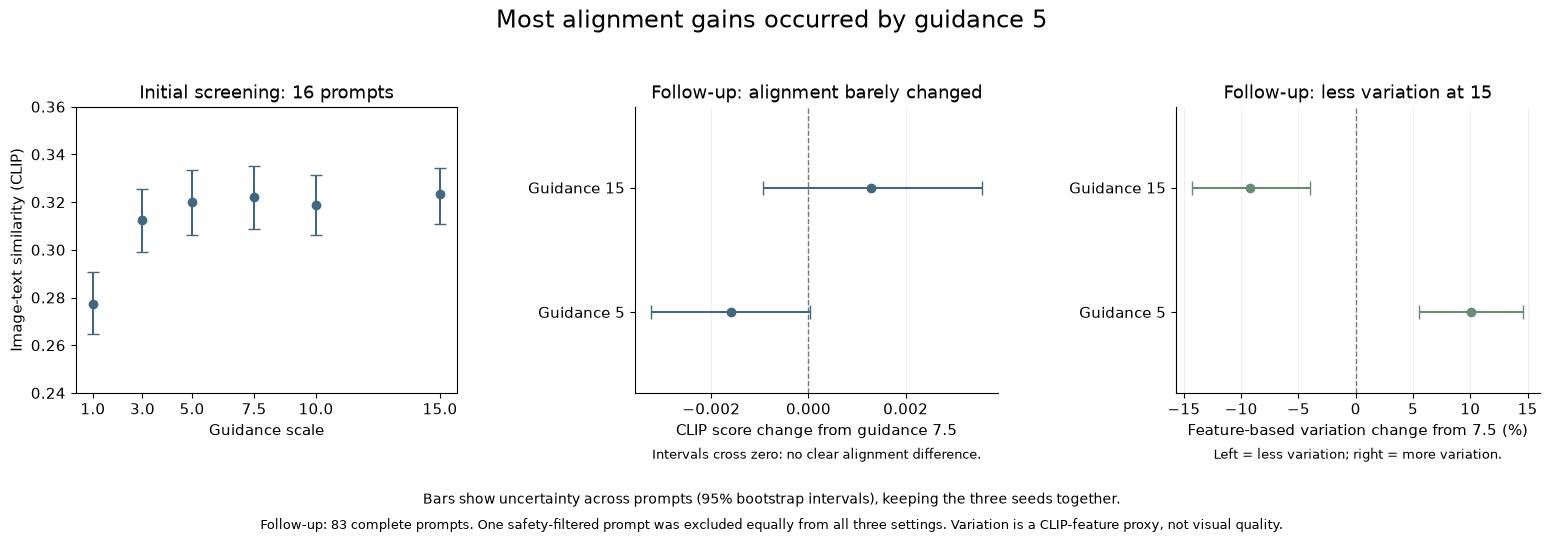

,guidance_scale,prompts,alignment_change,alignment_ci_low,alignment_ci_high,variation_change_percent,variation_ci_low,variation_ci_high
0,5.0,83,-0.001589,-0.003233,0.000039,10.025292,5.551878,14.599312
1,15.0,83,0.001282,-0.000936,0.003570,-9.246514,-14.250268,-3.990345


{
  "expected_images": 1044,
  "completed_images": 1044,
  "sweep_images": 288,
  "confirmation_images": 756,
  "safety_flags": 1,
  "blank_images": 1,
  "all_hashes_verified": true,
  "matched_initial_noise": true,
  "evaluation_used": false,
  "training_performed": false,
  "cached_scores_verified": true,
  "max_score_recalculation_error": 1.4901161199398771e-07,
  "mean_paired_clip": 0.3140005810063043,
  "mean_mismatched_clip": 0.143826750272301,
  "balanced_confirmation_prompts": 83
}


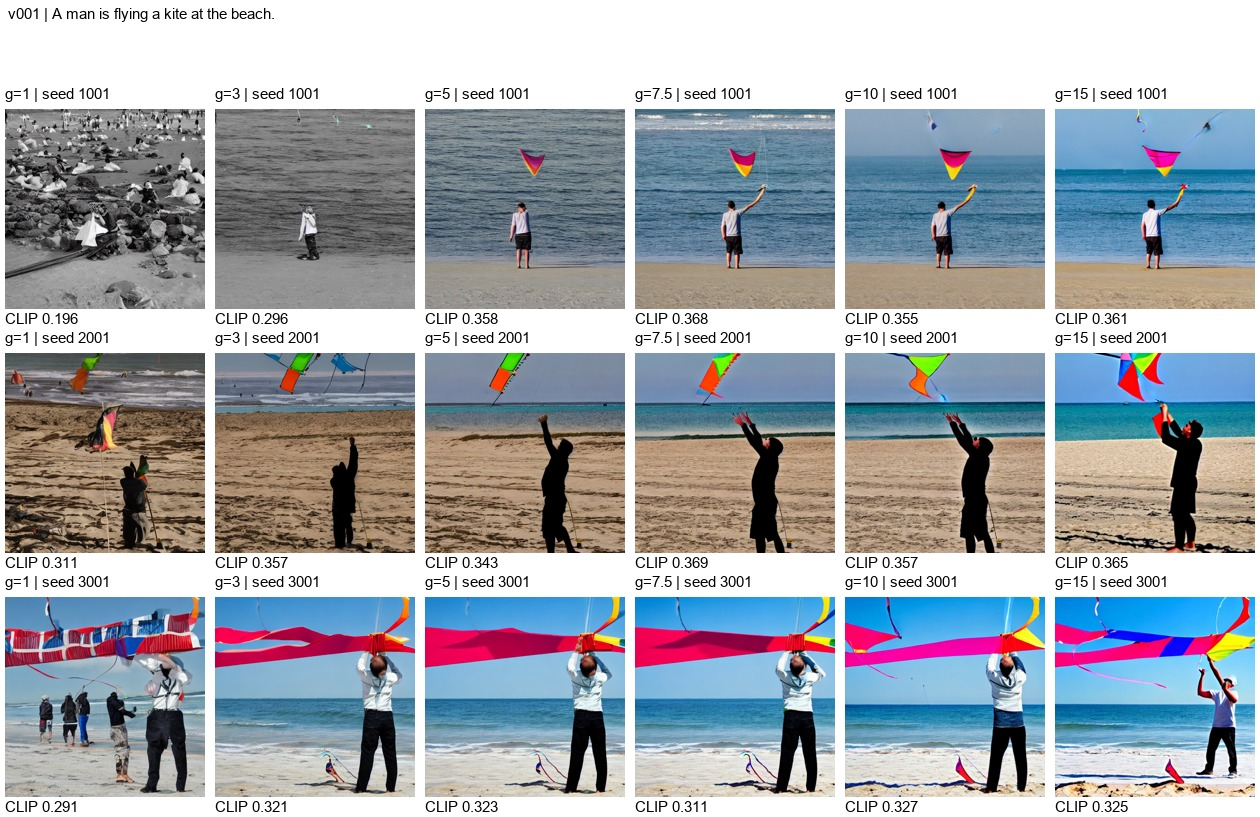

In [5]:
import textwrap
# Logged initial noise had to match across scales for each seed and prompt.
assert logs.groupby(['prompt_id','seed']).noise_sha256.nunique().eq(1).all()
assert not logs.duplicated(['phase','prompt_id','seed','guidance_scale']).any()
for row in logs.itertuples(index=False):
    path=OUT/row.image_file
    assert hashlib.sha256(path.read_bytes()).hexdigest()==row.image_sha256
    with Image.open(path) as im: assert im.mode=='RGB' and im.size==(512,512)
quality=dict(expected_images=1044,completed_images=len(logs),sweep_images=int(logs.phase.eq('sweep').sum()),
             confirmation_images=int(logs.phase.eq('confirmation').sum()),safety_flags=int(logs.safety_flag.sum()),
             blank_images=int(logs.all_black.sum()),all_hashes_verified=True,matched_initial_noise=True,
             evaluation_used=False,training_performed=False)
(OUT/'verification.json').write_text(json.dumps(quality,indent=2))
font=ImageFont.truetype('C:/Windows/Fonts/arial.ttf',15) if Path('C:/Windows/Fonts/arial.ttf').exists() else ImageFont.load_default(size=15)
(OUT/'galleries').mkdir(exist_ok=True)
def gallery(row,scales):
    width=210; height=244; header=85
    canvas=Image.new('RGB',(width*len(scales),header+height*3),'white'); draw=ImageDraw.Draw(canvas)
    draw.multiline_text((8,5),textwrap.fill(f'{row.prompt_id} | {row.prompt}',width=100),font=font,fill='black')
    for i,seed in enumerate(SEEDS):
        for j,scale in enumerate(scales):
            rec=logs.loc[logs.prompt_id.eq(row.prompt_id)&logs.seed.eq(seed)&logs.guidance_scale.eq(scale)].iloc[0]
            with Image.open(OUT/rec.image_file) as image:canvas.paste(image.resize((200,200)),(j*width+5,header+i*height+24))
            draw.text((j*width+5,header+i*height),f'g={scale:g} | seed {seed}',font=font,fill='black')
            draw.text((j*width+5,header+i*height+225),f'CLIP {rec.clip_cosine:.3f}',font=font,fill='black')
    canvas.save(OUT/'galleries'/f'{row.phase}_{row.prompt_id}.jpg',quality=92)
for row in validation.itertuples(index=False):gallery(row,SCALES if row.phase=='sweep' else selected)
# A separate calculation checked that saved features reproduced every logged score.
with torch.inference_mode():
    tokens = processor(text=validation.prompt.tolist(), padding=True, return_tensors='pt').to('cuda')
    text_vectors = torch.nn.functional.normalize(clip.get_text_features(**tokens), dim=-1).cpu().numpy()
index_by_id = {pid: i for i,pid in enumerate(validation.prompt_id)}
recomputed, mismatched = [], []
for row in logs.itertuples(index=False):
    vector = np.load((OUT/row.image_file).with_suffix('.npy'))
    assert vector.shape == (512,) and np.isfinite(vector).all()
    assert abs(np.linalg.norm(vector)-1) < 2e-5
    i = index_by_id[row.prompt_id]
    recomputed.append(float(vector @ text_vectors[i]))
    mismatched.append(float(vector @ text_vectors[(i+1)%100]))
max_error = float(np.max(np.abs(np.asarray(recomputed)-logs.clip_cosine.to_numpy())))
assert max_error < 2e-5
valid = ~logs.safety_flag.astype(bool) & ~logs.all_black.astype(bool)
assert np.mean(np.asarray(recomputed)[valid]) > np.mean(np.asarray(mismatched)[valid])
quality.update(cached_scores_verified=True, max_score_recalculation_error=max_error,
               mean_paired_clip=float(np.mean(np.asarray(recomputed)[valid])),
               mean_mismatched_clip=float(np.mean(np.asarray(mismatched)[valid])))
(OUT/'verification.json').write_text(json.dumps(quality,indent=2))
print('Saved-feature scores and mismatched-caption sanity check passed.')

# The balanced check used complete, valid three-seed groups at every scale.
confirmation_valid = logs.loc[logs.phase.eq('confirmation') & ~logs.safety_flag & ~logs.all_black]
diversity_rows = []
for (pid,scale), group in confirmation_valid.groupby(['prompt_id','guidance_scale']):
    if len(group) != 3: continue
    vectors = [np.load((OUT/f).with_suffix('.npy')) for f in group.image_file]
    distances = [1-np.dot(a,b) for a,b in itertools.combinations(vectors,2)]
    diversity_rows.append(dict(prompt_id=pid,guidance_scale=scale,diversity=np.mean(distances)))
diversity_wide = pd.DataFrame(diversity_rows).pivot(index='prompt_id',columns='guidance_scale',values='diversity').dropna()
balanced = confirmation_valid.loc[confirmation_valid.prompt_id.isin(diversity_wide.index)]
balanced.groupby('guidance_scale').agg(images=('seed','size'),mean_clip=('clip_cosine','mean')).to_csv(OUT/'balanced_confirmation_summary.csv')
rng = np.random.default_rng(42); diversity_intervals = []
for scale in [5.,7.5,15.]:
    delta = (diversity_wide[scale]-diversity_wide[7.5]).to_numpy()
    boot = rng.choice(delta,size=(10000,len(delta)),replace=True).mean(axis=1)
    diversity_intervals.append(dict(guidance_scale=scale,paired_prompts=len(delta),
        mean_diversity_difference=delta.mean(),ci_low=np.quantile(boot,.025),ci_high=np.quantile(boot,.975)))
pd.DataFrame(diversity_intervals).to_csv(OUT/'confirmation_diversity_differences.csv',index=False)
quality['balanced_confirmation_prompts'] = len(diversity_wide)
(OUT/'verification.json').write_text(json.dumps(quality,indent=2))

# Follow-up figures used exactly the same complete prompts at every setting.
alignment_wide = balanced.groupby(['prompt_id','guidance_scale']).clip_cosine.mean().unstack()
assert set(alignment_wide.index) == set(diversity_wide.index)
followup_rows=[]; rng=np.random.default_rng(42)
for scale in [5.,15.]:
    delta=(alignment_wide[scale]-alignment_wide[7.5]).to_numpy()
    draws=rng.integers(0,len(delta),size=(10000,len(delta)))
    boot=delta[draws].mean(axis=1)
    dv=(diversity_wide[scale]-diversity_wide[7.5]).to_numpy()
    base=diversity_wide[7.5].to_numpy()
    variation=100*dv.mean()/base.mean()
    variation_boot=100*dv[draws].mean(axis=1)/base[draws].mean(axis=1)
    followup_rows.append(dict(guidance_scale=scale,prompts=len(delta),
        alignment_change=delta.mean(),alignment_ci_low=np.quantile(boot,.025),alignment_ci_high=np.quantile(boot,.975),
        variation_change_percent=variation,variation_ci_low=np.quantile(variation_boot,.025),variation_ci_high=np.quantile(variation_boot,.975)))
followup=pd.DataFrame(followup_rows)
followup.to_csv(OUT/'balanced_followup_comparisons.csv',index=False)
wide_sweep=sweep.groupby(['prompt_id','guidance_scale']).clip_cosine.mean().unstack()
rng=np.random.default_rng(42);screen=[]
for scale in SCALES:
    values=wide_sweep[scale].to_numpy()
    boot=rng.choice(values,size=(10000,len(values)),replace=True).mean(axis=1)
    screen.append((scale,values.mean(),np.quantile(boot,.025),np.quantile(boot,.975)))
screen=np.asarray(screen)
plt.rcParams.update({'font.size':11})
fig,axes=plt.subplots(1,3,figsize=(16,5.4),gridspec_kw={'width_ratios':[1.05,1,1]})
fig.suptitle('Most alignment gains occurred by guidance 5',fontsize=17,y=.98)
axes[0].errorbar(screen[:,0],screen[:,1],yerr=[screen[:,1]-screen[:,2],screen[:,3]-screen[:,1]],
                 fmt='o',capsize=4,color='#42677e')
axes[0].set(title='Initial screening: 16 prompts',xlabel='Guidance scale',ylabel='Image-text similarity (CLIP)',xticks=SCALES,ylim=(.24,.36))
for ax in axes[1:]:
    ax.axvline(0,color='#777777',linestyle='--',linewidth=1)
    ax.set_yticks([0,1],['Guidance 5','Guidance 15'])
    ax.set_ylim(-.65,1.65)
    ax.grid(axis='x',alpha=.18)
    ax.spines[['top','right']].set_visible(False)
for i,row in enumerate(followup.itertuples(index=False)):
    axes[1].errorbar(row.alignment_change,i,xerr=[[row.alignment_change-row.alignment_ci_low],
        [row.alignment_ci_high-row.alignment_change]],fmt='o',capsize=5,color='#42677e')
    axes[2].errorbar(row.variation_change_percent,i,xerr=[[row.variation_change_percent-row.variation_ci_low],
        [row.variation_ci_high-row.variation_change_percent]],fmt='o',capsize=5,color='#688c76')
axes[1].set(title='Follow-up: alignment barely changed',xlabel='CLIP score change from guidance 7.5')
axes[2].set(title='Follow-up: less variation at 15',xlabel='Feature-based variation change from 7.5 (%)')
axes[1].text(.5,-.23,'Intervals cross zero: no clear alignment difference.',transform=axes[1].transAxes,ha='center',fontsize=9)
axes[2].text(.5,-.23,'Left = less variation; right = more variation.',transform=axes[2].transAxes,ha='center',fontsize=9)
fig.text(.5,.065,'Bars show uncertainty across prompts (95% bootstrap intervals), keeping the three seeds together.',ha='center',fontsize=10)
fig.text(.5,.018,'Follow-up: 83 complete prompts. One safety-filtered prompt was excluded equally from all three settings. Variation is a CLIP-feature proxy, not visual quality.',ha='center',fontsize=9)
fig.subplots_adjust(left=.065,right=.98,top=.80,bottom=.27,wspace=.48)
fig.savefig(OUT/'guidance_summary.png',dpi=150);plt.show()
display(followup)
from PIL import ImageDraw, ImageFont
font = ImageFont.truetype('C:/Windows/Fonts/arial.ttf',16) if Path('C:/Windows/Fonts/arial.ttf').exists() else ImageFont.load_default(size=16)
examples_canvas = Image.new('RGB',(1320,610),'white')
draw = ImageDraw.Draw(examples_canvas)
illustrations = [('v001',1001,'A man is flying a kite at the beach.'),
                 ('v047',2001,'Two large giraffes inside a fenced area interact with one another.')]
for row_index,(pid,seed,caption) in enumerate(illustrations):
    y=row_index*300
    draw.text((8,y+5),f'{pid} | seed {seed} | {caption}',font=font,fill='black')
    for j,scale in enumerate(SCALES):
        entry=logs.loc[logs.prompt_id.eq(pid)&logs.seed.eq(seed)&logs.guidance_scale.eq(scale)].iloc[0]
        draw.text((j*220+8,y+32),f'Guidance {scale:g}',font=font,fill='black')
        with Image.open(OUT/entry.image_file) as im:
            examples_canvas.paste(im.resize((210,210)),(j*220+5,y+58))
draw.text((8,584),'Illustrative examples from the full saved galleries; no seeds or outputs were replaced.',font=font,fill='black')
examples_canvas.save(OUT/'guidance_examples.png')


print(json.dumps(quality,indent=2))
display(Image.open(OUT/'galleries'/f'sweep_{validation.iloc[positions[0]].prompt_id}.jpg'))

## 6. Findings

Increasing guidance from 1 toward 5 improved the CLIP image-text score. Guidance 1 was noticeably weaker; the results did not suggest that every value from 1 to 5 worked equally well. Above about 5, further gains were small.

In the larger follow-up, 15 scored slightly higher than 7.5, but the difference was too small and uncertain to establish an improvement. Images also became more similar across random starting points as guidance increased.

| Guidance | Image-text score | Variation compared with 7.5 |
| --- | --- | --- |
| 5 | 0.3134 | About 10% more |
| 7.5 | 0.3150 | Reference setting |
| 15 | 0.3163 | About 9% less |

The table used 83 complete prompts equally across settings after one output was safety-filtered. CLIP measured image-text similarity and differences between image features; neither measure directly established visual quality.

The middle panel's uncertainty bars crossed zero: neither alternative showed a clear alignment difference from 7.5.

Moderate guidance clarified the kite scene. In the giraffe scene, higher guidance added an extra animal. Stronger guidance could therefore reinforce the general scene while making a specific detail wrong.

## Conclusion

Guidance 5-7.5 was a useful working range for this pipeline, although no optimal value was established. Guidance 15 offered no convincing alignment benefit to offset its lower measured variation and visible artifacts.